## Week 4 Assignment

### Harina Chohan - 666983

In this lab, you will build and fine-tune an image classification pipeline using a pre-trained deep convolutional neural network (ResNet50, InceptionV3, or DenseNet121) in TensorFlow. You will leverage the Ultralytics African
Wildlife Dataset AND augment it with any other dataset to include the two missing BIG 5 (i.e. Lion, and Leopard) to classify images of flagship African species. This assignment explores the practical impacts of feature extraction versus full network fine-tuning in low-resource ecological monitoring applications.



# Big 5 African Wildlife Classification: Feature Extraction vs Fine-Tuning (ResNet50)

**Goal:** classify 6 flagship species (buffalo, elephant, rhino, zebra from the *Ultralytics African Wildlife* dataset, plus lion and leopard from the *Kaggle Wildlife* dataset)
Other wildlife dataset from kaggle: https://www.kaggle.com/datasets/banuprasadb/wildlife-dataset/data


## 1. Setup

In [1]:
import os, glob, time, random, shutil, zipfile, collections
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from PIL import Image

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
IMG_SIZE = (224, 224)
BATCH = 32
print("TF", tf.__version__, "| GPUs:", tf.config.list_physical_devices('GPU'))

TF 2.20.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Download the datasets

### 2a. Ultralytics African Wildlife (buffalo, elephant, rhino, zebra)
This dataset is in YOLO *detection* format (images + `.txt` label files). For classification we assign each image the most frequent class id found in its label file.

In [2]:
URL = "https://github.com/ultralytics/assets/releases/download/v0.0.0/african-wildlife.zip"
!wget -q -nc {URL} -O african-wildlife.zip
!unzip -q -n african-wildlife.zip -d african_wildlife
UL_ROOT = "african_wildlife"
UL_CLASSES = ["buffalo", "elephant", "rhino", "zebra"]   # class ids 0-3 per Ultralytics yaml
!find {UL_ROOT} -maxdepth 3 -type d | head -20

african_wildlife
african_wildlife/labels
african_wildlife/labels/val
african_wildlife/labels/train
african_wildlife/labels/test
african_wildlife/images
african_wildlife/images/val
african_wildlife/images/train
african_wildlife/images/test


### 2b. Kaggle Wildlife dataset (lion, leopard)


In [3]:
!pip -q install kagglehub
import kagglehub
KG_ROOT = kagglehub.dataset_download("banuprasadb/wildlife-dataset")
print("Downloaded to:", KG_ROOT)
for root, dirs, files in os.walk(KG_ROOT):
    depth = root[len(KG_ROOT):].count(os.sep)
    if depth <= 3:
        n_img = len([f for f in files if f.lower().endswith(('.jpg','.jpeg','.png'))])
        print("  "*depth + os.path.basename(root) + f"/  ({n_img} images)")

Using Colab cache for faster access to the 'wildlife-dataset' dataset.
Downloaded to: /kaggle/input/wildlife-dataset
wildlife-dataset/  (0 images)
  valid/  (0 images)
    labels/  (0 images)
    images/  (1748 images)
  test/  (0 images)
    labels/  (0 images)
    images/  (1717 images)
  train/  (0 images)
    labels/  (0 images)
    images/  (13605 images)


## 3. Build one unified table of (filepath, label)
Pool *all* original splits and re-split manually (stratified 70/15/15) so that the six classes (big 5 + zebra) are consistently represented and nothing leaks between train/val/test.

In [4]:
IMG_EXT = ('.jpg', '.jpeg', '.png')
rows = []

# --- Ultralytics: label from YOLO txt ---
for img_path in glob.glob(f"{UL_ROOT}/**/*", recursive=True):
    if not img_path.lower().endswith(IMG_EXT): continue
    lbl_path = os.path.splitext(img_path.replace("/images/", "/labels/"))[0] + ".txt"
    if not os.path.exists(lbl_path): continue
    ids = [int(l.split()[0]) for l in open(lbl_path) if l.strip()]
    if not ids: continue
    cid = collections.Counter(ids).most_common(1)[0][0]
    rows.append((img_path, UL_CLASSES[cid], "ultralytics"))

# --- Kaggle: lion & leopard come from class-named folders ---
import yaml

# 1) Find the class-name list shipped with the dataset
yaml_path = glob.glob(f"{KG_ROOT}/**/data.yaml", recursive=True)[0]
names = yaml.safe_load(open(yaml_path))["names"]
names = list(names.values()) if isinstance(names, dict) else names
print("Kaggle classes:", names)

KG_WANT = {"lion": "lion", "leopard": "leopard"}   # lowercase class name -> chosen label

# 2) Label each image by the majority class in its YOLO label file
for img_path in glob.glob(f"{KG_ROOT}/**/*", recursive=True):
    if not img_path.lower().endswith(IMG_EXT): continue
    lbl_path = os.path.splitext(img_path.replace("/images/", "/labels/"))[0] + ".txt"
    if not os.path.exists(lbl_path): continue
    ids = [int(l.split()[0]) for l in open(lbl_path) if l.strip()]
    if not ids: continue
    cname = names[collections.Counter(ids).most_common(1)[0][0]].lower()
    if cname in KG_WANT:
        rows.append((img_path, KG_WANT[cname], "kaggle"))

df = pd.DataFrame(rows, columns=["path", "label", "source"])

# Balance: cap every class at 400 images
df = (df.groupby("label", group_keys=False)
        .apply(lambda g: g.sample(min(len(g), 400), random_state=SEED))
        .reset_index(drop=True))

# Drop unreadable / corrupt images
def ok(p):
    try:
        with Image.open(p) as im: im.verify()
        return True
    except Exception: return False
df = df[df.path.map(ok)].reset_index(drop=True)

CLASSES = sorted(df.label.unique())
cid = {c: i for i, c in enumerate(CLASSES)}
df["y"] = df.label.map(cid)
print(CLASSES)
print(df.groupby(["label", "source"]).size().unstack(fill_value=0))
assert len(CLASSES) == 6, "Expected 6 classes - check the Kaggle folder names printed above"


Kaggle classes: ['Zebra', 'Lion', 'Leopard', 'Cheetah', 'Tiger', 'Bear', 'Butterfly', 'Canary', 'Crocodile', 'Bull', 'Camel', 'Centipede', 'Caterpillar', 'Duck', 'Squirrel', 'Spider', 'Ladybug', 'Elephant', 'Horse', 'Fox', 'Tortoise', 'Frog', 'Kangaroo', 'Deer', 'Eagle', 'Monkey', 'Snake', 'Owl', 'Swan', 'Goat', 'Rabbit', 'Giraffe', 'Goose', 'PolarBear', 'Raven', 'Hippopotamus', 'BrownBear', 'Rhinoceros', 'Woodpecker', 'Sheep', 'Magpie', 'Ostrich', 'Jaguar', 'Hedgehog', 'Turkey', 'Raccoon', 'Worm', 'Harbor', 'Panda', 'RedPanda', 'Otter', 'Lynx', 'Scorpion', 'Koala']


/tmp/ipykernel_6655/3248153844.py:40: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(len(g), 400), random_state=SEED))


['buffalo', 'elephant', 'leopard', 'lion', 'rhino', 'zebra']
source    kaggle  ultralytics
label                        
buffalo        0          374
elephant       0          374
leopard      177            0
lion         307            0
rhino          0          371
zebra          0          385


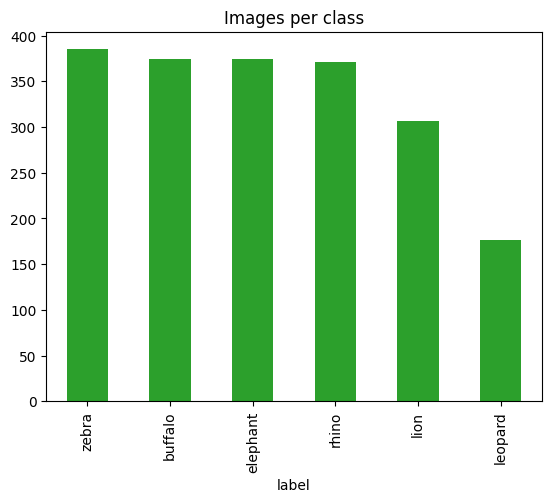

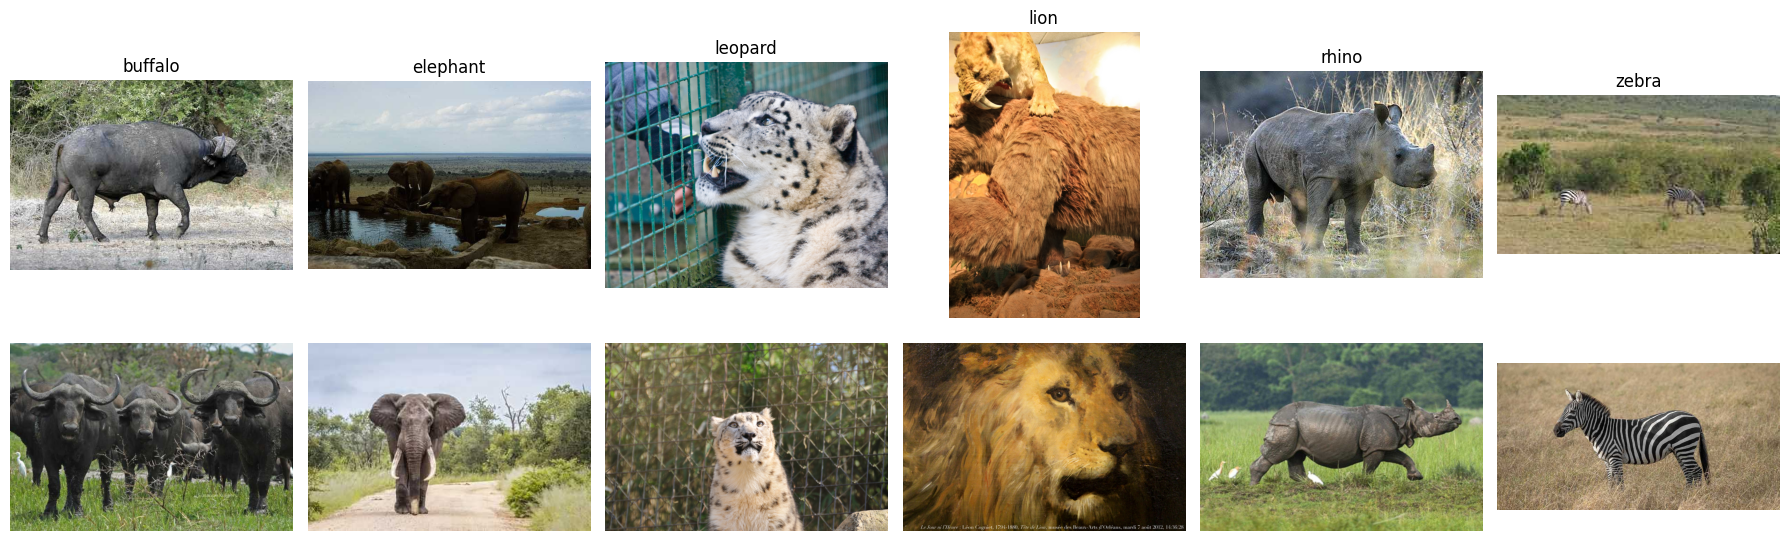

In [5]:
df["label"].value_counts().plot.bar(title="Images per class", color="tab:green"); plt.show()

fig, axes = plt.subplots(2, 6, figsize=(18, 6))
for j, c in enumerate(CLASSES):
    for i, (_, r) in enumerate(df[df.label == c].sample(2, random_state=SEED).iterrows()):
        axes[i, j].imshow(Image.open(r.path).convert("RGB")); axes[i, j].axis("off")
        if i == 0: axes[i, j].set_title(c)
plt.tight_layout(); plt.show()

In [6]:
print(df[df.source == "kaggle"].assign(folder=lambda d: d.path.map(
    lambda p: os.path.relpath(os.path.dirname(p), KG_ROOT))).groupby(["label", "folder"]).size())

label    folder      
leopard  test/images      17
         train/images    147
         valid/images     13
lion     test/images      40
         train/images    237
         valid/images     30
dtype: int64


## 4. Stratified split and `tf.data` pipelines

In [7]:
train_df, tmp = train_test_split(df, test_size=0.30, stratify=df.y, random_state=SEED)
val_df, test_df = train_test_split(tmp, test_size=0.50, stratify=tmp.y, random_state=SEED)
print(len(train_df), len(val_df), len(test_df))

AUTOTUNE = tf.data.AUTOTUNE
def load(path, y):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    img.set_shape((*IMG_SIZE, 3))
    return img, y

def make_ds(d, train=False):
    ds = tf.data.Dataset.from_tensor_slices((d.path.values, d.y.values))
    if train: ds = ds.shuffle(len(d), seed=SEED)
    ds = ds.map(load, num_parallel_calls=AUTOTUNE).batch(BATCH)
    return ds.prefetch(AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(train_df, True), make_ds(val_df), make_ds(test_df)

# Class weights to counter imbalance
cw = (len(train_df) / (len(CLASSES) * train_df.y.value_counts().sort_index())).to_dict()
print("class weights:", {CLASSES[k]: round(v, 2) for k, v in cw.items()})

1391 298 299
class weights: {'buffalo': 0.88, 'elephant': 0.88, 'leopard': 1.87, 'lion': 1.08, 'rhino': 0.9, 'zebra': 0.86}


## 5. Model builder (ResNet50, ImageNet weights)

In [8]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.15),
], name="augmentation")

def build_model(dropout=0.3):
    base = keras.applications.ResNet50(include_top=False, weights="imagenet",
                                       input_shape=(*IMG_SIZE, 3))
    base.trainable = False
    inp = keras.Input((*IMG_SIZE, 3))
    x = augment(inp)
    x = keras.applications.resnet50.preprocess_input(x)
    x = base(x, training=False)          # keeps BatchNorm in inference mode, even when unfrozen
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(len(CLASSES), activation="softmax")(x)
    return keras.Model(inp, out), base

def set_trainable(base, mode):
    if mode == "head":
        base.trainable = False
    elif mode == "partial":                       # unfreeze last stage (conv5_*)
        base.trainable = True
        for l in base.layers:
            l.trainable = l.name.startswith("conv5")
    elif mode == "full":
        base.trainable = True
    # BatchNorm layers stay frozen (stable statistics for small datasets)
    for l in base.layers:
        if isinstance(l, layers.BatchNormalization): l.trainable = False

def compile_model(model, lr):
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])

def n_trainable(model):
    return int(sum(np.prod(w.shape) for w in model.trainable_weights))

results, histories, preds = {}, {}, {}

def evaluate(name, model, secs):
    y_true = np.concatenate([y.numpy() for _, y in test_ds])
    y_pred = model.predict(test_ds, verbose=0).argmax(1)
    results[name] = dict(
        test_acc=float((y_true == y_pred).mean()),
        macro_f1=f1_score(y_true, y_pred, average="macro"),
        trainable_params=n_trainable(model), train_time_s=round(secs, 1))
    preds[name] = (y_true, y_pred)
    print(name, results[name])

def callbacks(path):
    return [keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True, monitor="val_loss"),
            keras.callbacks.ReduceLROnPlateau(factor=0.3, patience=2, verbose=1),
            keras.callbacks.ModelCheckpoint(path, save_best_only=True, save_weights_only=True)]

## 6. Experiment A: Feature extraction (frozen backbone)
The backbone is a fixed feature extractor; only the 2048→6 dense head learns. Fast and low-risk, but the features were learned on ImageNet and are not adapted to wildlife.

In [9]:
modelA, baseA = build_model()
set_trainable(baseA, "head"); compile_model(modelA, 1e-3)
t = time.time()
histories["A_feature_extraction"] = modelA.fit(
    train_ds, validation_data=val_ds, epochs=15, class_weight=cw,
    callbacks=callbacks("A.weights.h5"), verbose=2).history
evaluate("A_feature_extraction", modelA, time.time() - t)

Epoch 1/15
44/44 - 38s - 874ms/step - accuracy: 0.7405 - loss: 0.7251 - val_accuracy: 0.9631 - val_loss: 0.1445 - learning_rate: 0.0010
Epoch 2/15
44/44 - 9s - 215ms/step - accuracy: 0.9281 - loss: 0.2175 - val_accuracy: 0.9732 - val_loss: 0.0991 - learning_rate: 0.0010
Epoch 3/15
44/44 - 9s - 215ms/step - accuracy: 0.9482 - loss: 0.1644 - val_accuracy: 0.9799 - val_loss: 0.0913 - learning_rate: 0.0010
Epoch 4/15
44/44 - 8s - 190ms/step - accuracy: 0.9533 - loss: 0.1491 - val_accuracy: 0.9765 - val_loss: 0.0770 - learning_rate: 0.0010
Epoch 5/15
44/44 - 10s - 224ms/step - accuracy: 0.9676 - loss: 0.1201 - val_accuracy: 0.9866 - val_loss: 0.0700 - learning_rate: 0.0010
Epoch 6/15
44/44 - 9s - 211ms/step - accuracy: 0.9612 - loss: 0.1160 - val_accuracy: 0.9899 - val_loss: 0.0654 - learning_rate: 0.0010
Epoch 7/15
44/44 - 8s - 177ms/step - accuracy: 0.9684 - loss: 0.0916 - val_accuracy: 0.9799 - val_loss: 0.0808 - learning_rate: 0.0010
Epoch 8/15
44/44 - 10s - 224ms/step - accuracy: 0.959

## 7. Experiment B: Partial fine-tuning (`conv5` block + head)
Warm-start from the trained head of Experiment A (avoids large random-head gradients wrecking pretrained features), then unfreeze the last residual stage with a **much smaller learning rate**.

In [10]:
modelB, baseB = build_model()
modelB.load_weights("A.weights.h5")
set_trainable(baseB, "partial"); compile_model(modelB, 1e-5 * 5)
t = time.time()
histories["B_partial_finetune"] = modelB.fit(
    train_ds, validation_data=val_ds, epochs=15, class_weight=cw,
    callbacks=callbacks("B.weights.h5"), verbose=2).history
evaluate("B_partial_finetune", modelB, time.time() - t + 0)  # fine-tune stage time only

Epoch 1/15
44/44 - 27s - 604ms/step - accuracy: 0.9590 - loss: 0.1104 - val_accuracy: 0.9866 - val_loss: 0.0598 - learning_rate: 5.0000e-05
Epoch 2/15
44/44 - 12s - 265ms/step - accuracy: 0.9827 - loss: 0.0549 - val_accuracy: 0.9866 - val_loss: 0.0556 - learning_rate: 5.0000e-05
Epoch 3/15
44/44 - 12s - 274ms/step - accuracy: 0.9827 - loss: 0.0469 - val_accuracy: 0.9899 - val_loss: 0.0427 - learning_rate: 5.0000e-05
Epoch 4/15
44/44 - 10s - 219ms/step - accuracy: 0.9899 - loss: 0.0266 - val_accuracy: 0.9765 - val_loss: 0.0699 - learning_rate: 5.0000e-05
Epoch 5/15

Epoch 5: ReduceLROnPlateau reducing learning rate to 1.4999999621068127e-05.
44/44 - 10s - 230ms/step - accuracy: 0.9907 - loss: 0.0205 - val_accuracy: 0.9799 - val_loss: 0.0642 - learning_rate: 5.0000e-05
Epoch 6/15
44/44 - 10s - 220ms/step - accuracy: 0.9964 - loss: 0.0109 - val_accuracy: 0.9799 - val_loss: 0.0444 - learning_rate: 1.5000e-05
Epoch 7/15
44/44 - 11s - 259ms/step - accuracy: 0.9971 - loss: 0.0096 - val_accura

## 8. Experiment C: Full fine-tuning (all layers)

In [11]:
modelC, baseC = build_model()
modelC.load_weights("A.weights.h5")
set_trainable(baseC, "full"); compile_model(modelC, 1e-5)
t = time.time()
histories["C_full_finetune"] = modelC.fit(
    train_ds, validation_data=val_ds, epochs=15, class_weight=cw,
    callbacks=callbacks("C.weights.h5"), verbose=2).history
evaluate("C_full_finetune", modelC, time.time() - t)

Epoch 1/15
44/44 - 54s - 1s/step - accuracy: 0.9777 - loss: 0.0674 - val_accuracy: 0.9866 - val_loss: 0.0636 - learning_rate: 1.0000e-05
Epoch 2/15
44/44 - 18s - 414ms/step - accuracy: 0.9741 - loss: 0.0568 - val_accuracy: 0.9799 - val_loss: 0.0732 - learning_rate: 1.0000e-05
Epoch 3/15
44/44 - 19s - 439ms/step - accuracy: 0.9885 - loss: 0.0359 - val_accuracy: 0.9832 - val_loss: 0.0601 - learning_rate: 1.0000e-05
Epoch 4/15
44/44 - 17s - 381ms/step - accuracy: 0.9892 - loss: 0.0285 - val_accuracy: 0.9799 - val_loss: 0.0700 - learning_rate: 1.0000e-05
Epoch 5/15
44/44 - 19s - 441ms/step - accuracy: 0.9935 - loss: 0.0203 - val_accuracy: 0.9866 - val_loss: 0.0491 - learning_rate: 1.0000e-05
Epoch 6/15
44/44 - 17s - 382ms/step - accuracy: 0.9921 - loss: 0.0238 - val_accuracy: 0.9866 - val_loss: 0.0595 - learning_rate: 1.0000e-05
Epoch 7/15

Epoch 7: ReduceLROnPlateau reducing learning rate to 2.9999999242136253e-06.
44/44 - 17s - 385ms/step - accuracy: 0.9928 - loss: 0.0150 - val_accuracy:

## 9. Results and comparison

,test_acc,macro_f1,trainable_params,train_time_s
A_feature_extraction,0.9799,0.9786,12294.0,167.9
B_partial_finetune,0.9766,0.9738,14965766.0,151.0
C_full_finetune,0.9833,0.9837,23493766.0,313.7


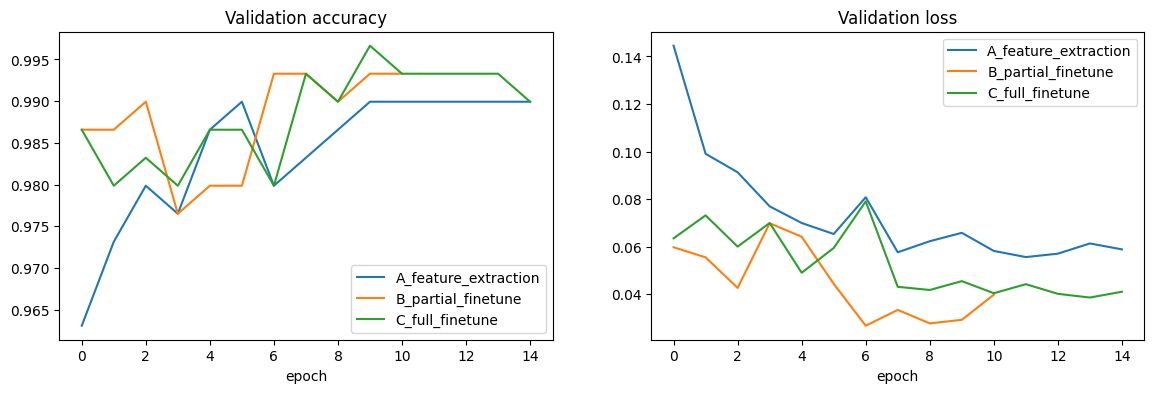

In [12]:
res = pd.DataFrame(results).T
res["test_acc"] = res.test_acc.round(4); res["macro_f1"] = res.macro_f1.round(4)
display(res)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for n, h in histories.items():
    ax[0].plot(h["val_accuracy"], label=n); ax[1].plot(h["val_loss"], label=n)
ax[0].set_title("Validation accuracy"); ax[1].set_title("Validation loss")
for a in ax: a.set_xlabel("epoch"); a.legend()
plt.show()

 A_feature_extraction
              precision    recall  f1-score   support

     buffalo      1.000     0.964     0.982        56
    elephant      0.982     0.982     0.982        56
     leopard      1.000     0.926     0.962        27
        lion      0.979     1.000     0.989        46
       rhino      0.966     1.000     0.982        56
       zebra      0.966     0.983     0.974        58

    accuracy                          0.980       299
   macro avg      0.982     0.976     0.979       299
weighted avg      0.980     0.980     0.980       299

 B_partial_finetune
              precision    recall  f1-score   support

     buffalo      1.000     0.964     0.982        56
    elephant      0.965     0.982     0.973        56
     leopard      1.000     0.889     0.941        27
        lion      0.979     1.000     0.989        46
       rhino      0.966     1.000     0.982        56
       zebra      0.966     0.983     0.974        58

    accuracy                       

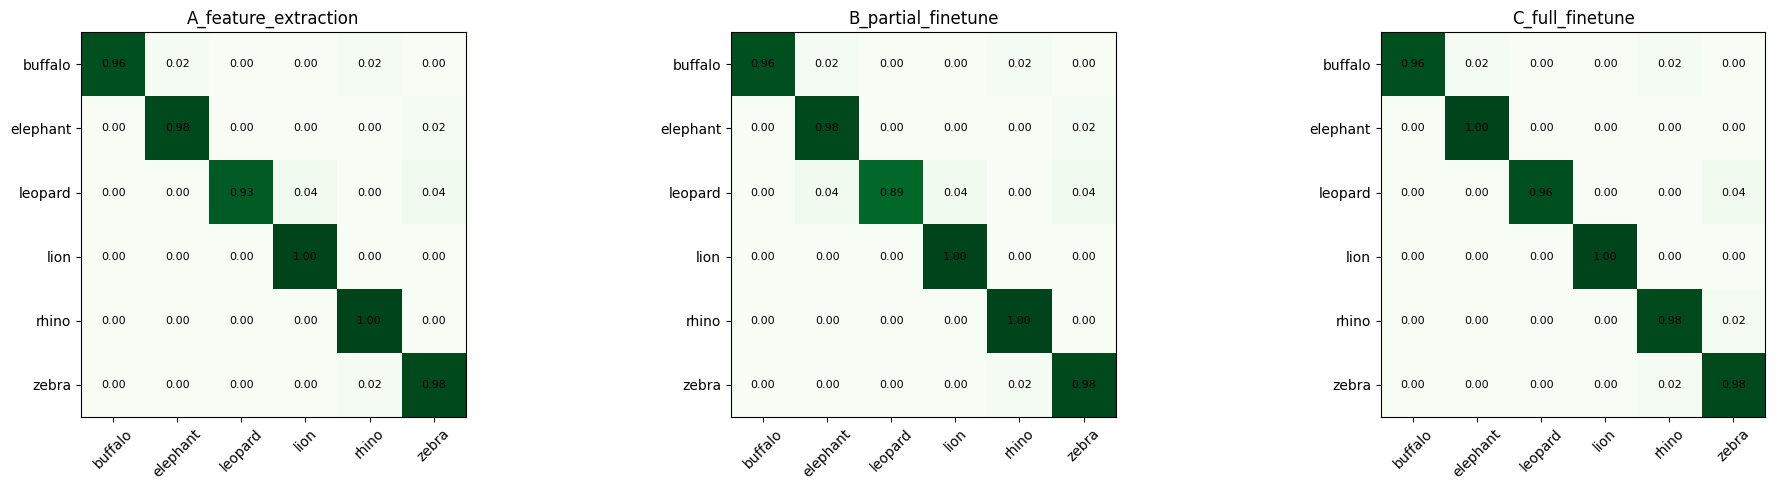

In [13]:
for name, (yt, yp) in preds.items():
    print("="*70, "\n", name)
    print(classification_report(yt, yp, target_names=CLASSES, digits=3))

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, (name, (yt, yp)) in zip(axes, preds.items()):
    cm = confusion_matrix(yt, yp, normalize="true")
    ax.imshow(cm, cmap="Greens"); ax.set_title(name)
    ax.set_xticks(range(6)); ax.set_xticklabels(CLASSES, rotation=45)
    ax.set_yticks(range(6)); ax.set_yticklabels(CLASSES)
    for i in range(6):
        for j in range(6): ax.text(j, i, f"{cm[i,j]:.2f}", ha="center", va="center", fontsize=8)
plt.tight_layout(); plt.show()

## 10. Inspect errors of the best model

Best: C_full_finetune


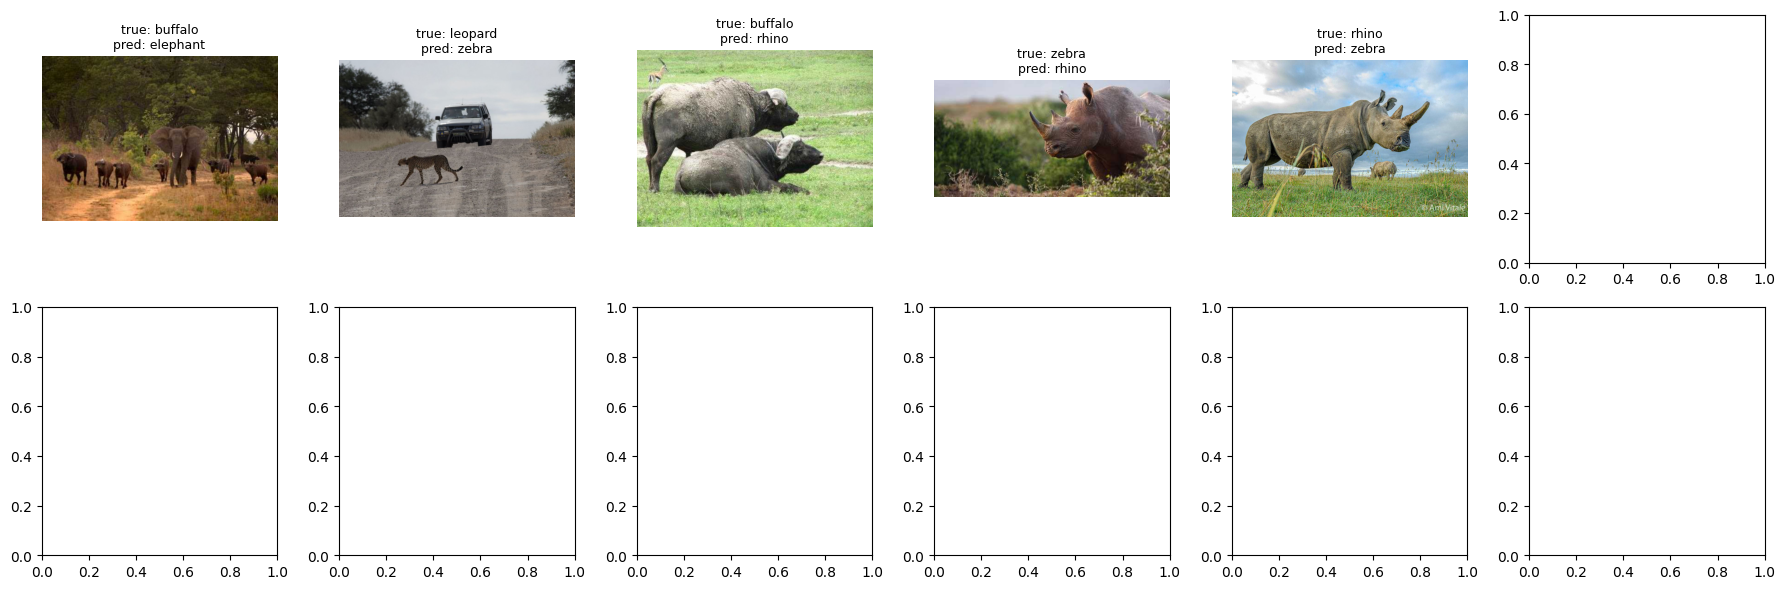

In [14]:
best = res.macro_f1.astype(float).idxmax(); print("Best:", best)
best_model = {"A_feature_extraction": modelA, "B_partial_finetune": modelB, "C_full_finetune": modelC}[best]
yt, yp = preds[best]
wrong = np.where(yt != yp)[0][:12]
paths = test_df.path.values   # test_ds is unshuffled, so order matches test_df
fig, axes = plt.subplots(2, 6, figsize=(18, 6))
for ax, i in zip(axes.ravel(), wrong):
    ax.imshow(Image.open(paths[i]).convert("RGB")); ax.axis("off")
    ax.set_title(f"true: {CLASSES[yt[i]]}\npred: {CLASSES[yp[i]]}", fontsize=9)
plt.tight_layout(); plt.show()

best_model.save_weights("best_big5.weights.h5")
for ax in axes.ravel()[len(wrong):]:
    ax.axis("off")

## 11. Conclusion and insights


test accuracy of all three (feature extraction, partial finetune and full finetune) were very similar at 0.9799, 0.9766, 0.9833 respectively. Full finetune was marginally more accurate, however, it took double the time to train compared to feature extraction.
However, when comparing validation loss, full finetune had a significantly lower loss value compared to the other two. According to me, the extra training time and parameters is not worth for an accuracy difference of 0.0034.


According to the calculated figures from the classification report, full finetune is the best weightage for these datasets and classification problem. There is a little bit of imbalance with the dataset as there are significantly fewer lion and leopard pictures from the Kaggle dataset compared to the other animal classes from the Ultralytics dataset. The support for leopard specifically is around half of what the buffalo, elephant, rhino, and zebra numbers are. More leopard and lion pictures would make this more balanced.


There is a possibility of the model learning the "source" cues like image size, framing and color tone rather than the species, since there are two different sources being used here. Some examples of this are the wrongly predicted species:
1. picture is one of a herd of elephants that were predicted as buffaloes. At the
EDA images there is a herd of buffaloes similar framing to that of the elephant which could show that the model is learning that instead of the species.
2. Second is of a leopard crossing the road in front of a car where the model wrongly predicted it as a zebra. It is possible that the leopard pictures may be more closeups and not from far and that's why it was predicted that way.
3. The buffaloes that were just 2 and not in a herd like expected, so they must be rhinos. They were sat like a rhino would be and have the same color tone.
These show that the model may not be finding landmark characteristics of each species to identify them like tusks or trunk for an elephant, stripes for the zebra, horns of the buffalo, spots of the leopard etc but more general idea of the picture. This could be a problem that points to overfitting that should be looked into.

Recommendation is to have more variety in the picture data (especially for the leopard and perhaps try other models to compare their workings. However, this did perform very well with a 98% accuracy, and because the total number of photos used was 1,988 only, it was not very computationally costly.
Also, it will be an interesting experiment to try if a model can differentiate between a leopard and a cheetah as they have very similar characteristics